In [11]:
import zipfile
import os
import pandas as pd

# Extract the Kaggle dataset
with zipfile.ZipFile("archive (6).zip", "r") as zip_ref:
    zip_ref.extractall("diabetes_data")

# Find the CSV file automatically
files = os.listdir("diabetes_data")
print("Extracted files:", files)

# Load the CSV
csv_file = [f for f in files if f.endswith(".csv")][0]
df = pd.read_csv("diabetes_data/" + csv_file)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Extracted files: ['diabetes_prediction_dataset.csv']
Dataset loaded successfully!
Shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [12]:
# Check dataset information

print("Dataset Information:")
print(df.info())

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
None

Column Names:
Index(['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes'],
      dtype='object')

Missing Values:
gender                 0
age                   

In [13]:
# Statistical summary of numerical columns

df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [14]:
# Check diabetes distribution

print(df["diabetes"].value_counts())

print("\nPercentage:")
print(df["diabetes"].value_counts(normalize=True) * 100)

diabetes
0    91500
1     8500
Name: count, dtype: int64

Percentage:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


In [15]:
# Remove duplicate rows

before = df.shape[0]

df = df.drop_duplicates()

after = df.shape[0]

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicates removed:", before - after)

Rows before removing duplicates: 100000
Rows after removing duplicates: 96146
Duplicates removed: 3854


In [16]:
# Check missing values after removing duplicates

print(df.isnull().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


In [17]:
# Check unique values in categorical columns

print("Gender:", df["gender"].unique())
print("Smoking History:", df["smoking_history"].unique())

Gender: ['Female' 'Male' 'Other']
Smoking History: ['never' 'No Info' 'current' 'former' 'ever' 'not current']


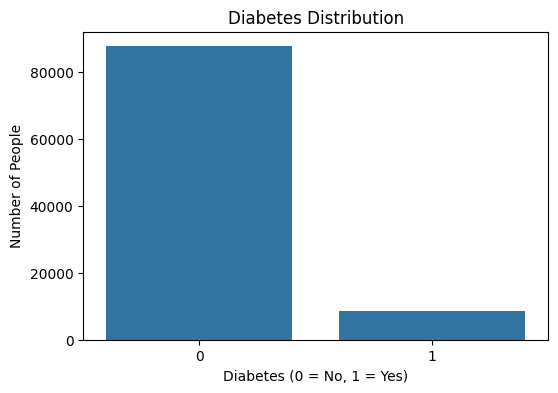

In [18]:
plt.figure(figsize=(6,4))

sns.countplot(x="diabetes", data=df)

plt.title("Diabetes Distribution")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Number of People")
plt.show()

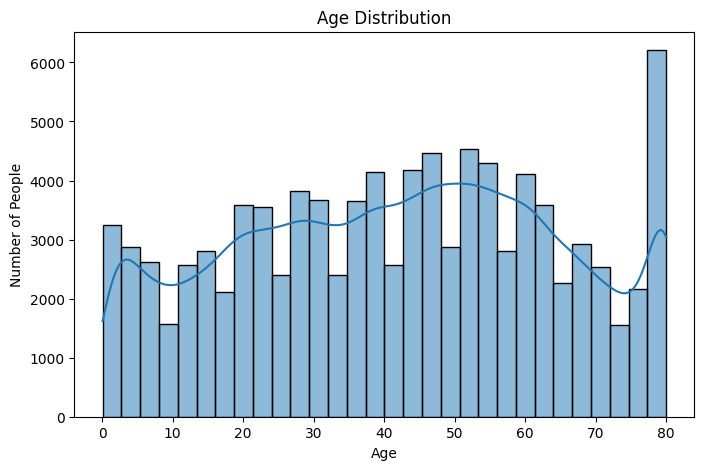

In [19]:
plt.figure(figsize=(8,5))

sns.histplot(df["age"], bins=30, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of People")
plt.show()

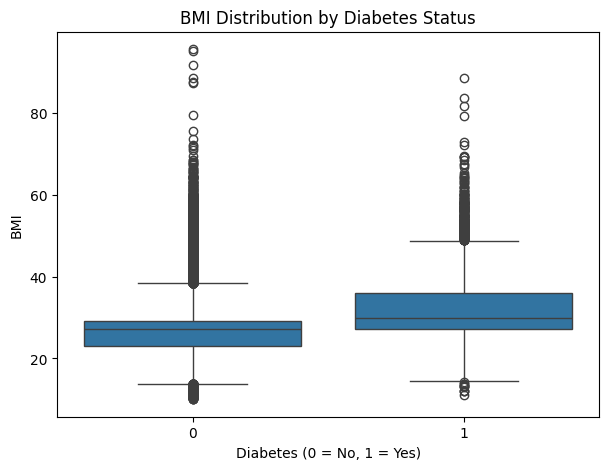

In [20]:
plt.figure(figsize=(7,5))

sns.boxplot(x="diabetes", y="bmi", data=df)

plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("BMI")
plt.show()

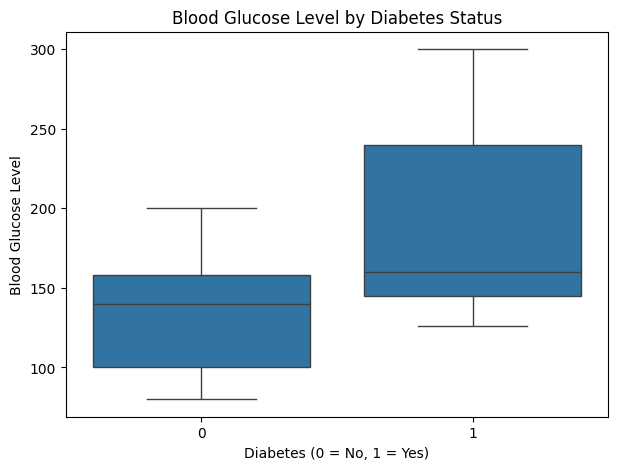

In [21]:
plt.figure(figsize=(7,5))

sns.boxplot(x="diabetes", y="blood_glucose_level", data=df)

plt.title("Blood Glucose Level by Diabetes Status")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("Blood Glucose Level")
plt.show()

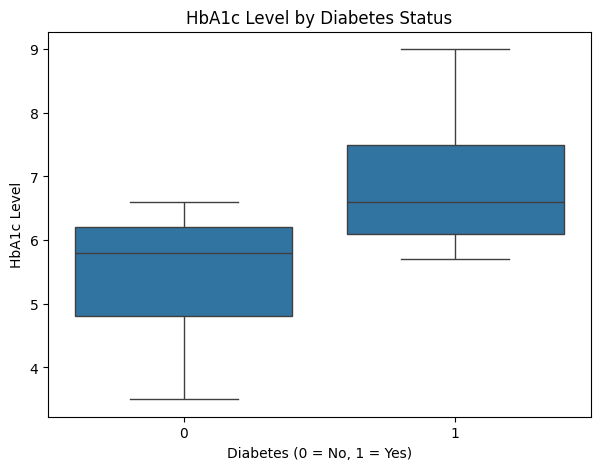

In [22]:
plt.figure(figsize=(7,5))

sns.boxplot(x="diabetes", y="HbA1c_level", data=df)

plt.title("HbA1c Level by Diabetes Status")
plt.xlabel("Diabetes (0 = No, 1 = Yes)")
plt.ylabel("HbA1c Level")
plt.show()

In [23]:
# Convert categorical columns into numerical form

df_encoded = pd.get_dummies(
    df,
    columns=["gender", "smoking_history"],
    drop_first=True
)

print("New dataset shape:", df_encoded.shape)
df_encoded.head()

New dataset shape: (96146, 14)


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,80.0,0,1,25.19,6.6,140,0,False,False,False,False,False,True,False
1,54.0,0,0,27.32,6.6,80,0,False,False,False,False,False,False,False
2,28.0,0,0,27.32,5.7,158,0,True,False,False,False,False,True,False
3,36.0,0,0,23.45,5.0,155,0,False,False,True,False,False,False,False
4,76.0,1,1,20.14,4.8,155,0,True,False,True,False,False,False,False


In [24]:
# Separate input features (X) and target (y)

X = df_encoded.drop("diabetes", axis=1)
y = df_encoded["diabetes"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (96146, 13)
Target shape: (96146,)


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (76916, 13)
Testing data: (19230, 13)


In [26]:
from sklearn.ensemble import GradientBoostingClassifier

# Create the Gradient Boosting model
gb_model = GradientBoostingClassifier(random_state=42)

# Train the model
gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [27]:
# Predict diabetes for the test data

y_pred = gb_model.predict(X_test)

print("Predictions completed!")
print(y_pred[:10])

Predictions completed!
[0 0 0 0 0 0 0 0 0 0]


In [28]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9718148725949038

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.99      0.69      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.98      0.84      0.90     19230
weighted avg       0.97      0.97      0.97     19230



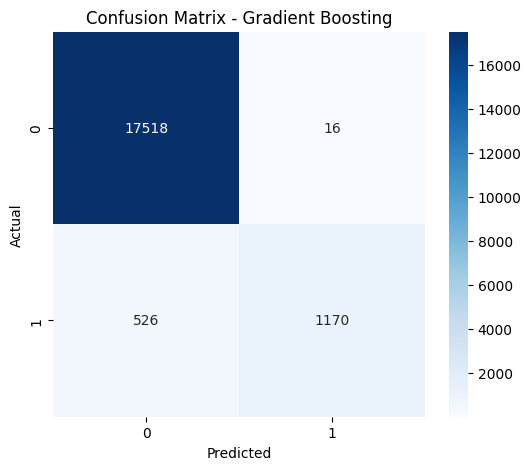

In [29]:
plt.figure(figsize=(6,5))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix - Gradient Boosting")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [30]:
# Find the most important features

importance = pd.Series(
    gb_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

HbA1c_level                    0.635478
blood_glucose_level            0.319143
age                            0.027725
bmi                            0.009702
hypertension                   0.004353
heart_disease                  0.002770
gender_Male                    0.000290
smoking_history_never          0.000236
smoking_history_former         0.000127
smoking_history_current        0.000110
smoking_history_ever           0.000045
smoking_history_not current    0.000020
gender_Other                   0.000000
dtype: float64


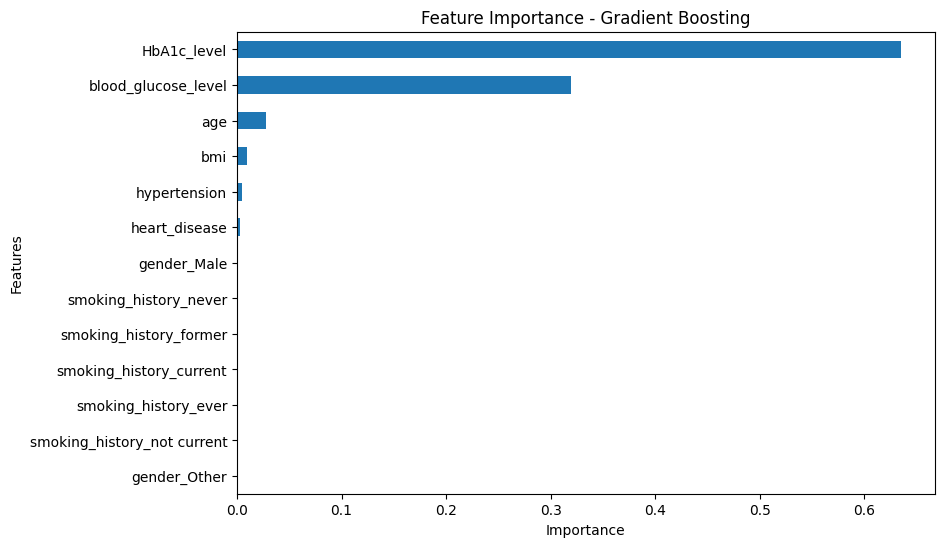

In [31]:
plt.figure(figsize=(9,6))

importance.sort_values(ascending=True).plot(kind="barh")

plt.title("Feature Importance - Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

In [32]:
# Save the processed dataset

df_encoded.to_csv("diabetes_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


Conclusion

This project used the Kaggle Diabetes Prediction Dataset to study and predict diabetes using machine learning. The data was cleaned and analyzed to understand important patterns and relationships between the features and diabetes.

Different visualizations helped us understand factors such as age, BMI, HbA1c level, and blood glucose level. A Gradient Boosting Classifier was then trained to predict whether a person has diabetes.

The model was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. Overall, the project helped us understand how data analysis and boosting techniques can be applied to a healthcare-related prediction problem.

One limitation is that the model should not be considered a replacement for professional medical diagnosis. In the future, the project could be improved by trying other boosting algorithms, tuning the model parameters, and testing the model on additional real-world data.